In [1]:
import xarray as xr
from pystac_client import Client
catalog = Client.open("https://eoapi.workspace.earthcode.eox.at/stac/")
item = next(catalog.search(collections=["d13c-ch4-signatures-smart-ch4"]).items())
item

/opt/miniconda3/envs/pangeo/lib/python3.13/site-packages/xarray/backends/scipy_.py:39: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.io import netcdf_file as netcdf_file_base


<Item id=d13c-ch4-signatures-smart-ch4-zarr>

In [ ]:
item.assets["data"].href

In [2]:
ds = xr.open_zarr(item.assets["data"].href)
ds

<xarray.Dataset> Size: 3GB
Dimensions:                                  (time: 300, latitude: 180,
                                              longitude: 360)
Coordinates:
  * time                                     (time) datetime64[ns] 2kB 1998-0...
  * latitude                                 (latitude) float64 1kB -89.5 ......
  * longitude                                (longitude) float64 3kB -179.5 ....
Data variables: (12/17)
    sign_d13c_agw                            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_bb                             (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_ffg                            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_nat                            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_agricultural_waste  (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_biomassbiofuels     (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    ...                                       ...
    sign_d13c_sub_sector_oilandgas           (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_rice                (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_termites            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_waste_water         (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_sub_sector_wetlands            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
    sign_d13c_wet                            (time, latitude, longitude) float64 156MB dask.array<chunksize=(12, 90, 180), meta=np.ndarray>
Attributes:
    conventions:                      CF-1.9
    created_by:                       Emeline Tapin on 29 September 2025
    creator_email:                    emeline.tapin@lsce.ipsl.fr
    fluxes_source_for_flux_weighted:  AGRICULTURAL_WASTE, BIOFUELS, BIOMASS, ...
    history:                          Sub-sectors aggregated into sectors (fl...
    institution:                      LSCE (Laboratoire des Sciences du Clima...
    signature_source:                 LIVESTOCK, BIOFUELS, BIOMASS: LAN ET. A...
    time_period:                      Monthly data for 1998-2022
    title:                            d13C(CH4) isotopic signature

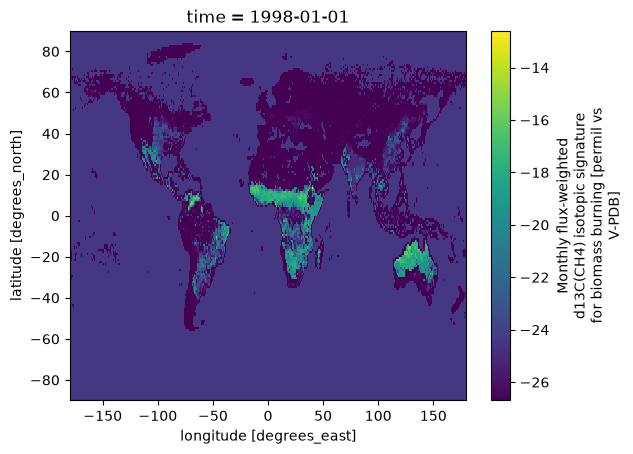

In [2]:
import cartopy.crs as ccrs
ds['sign_d13c_bb'].isel(time=0).plot()

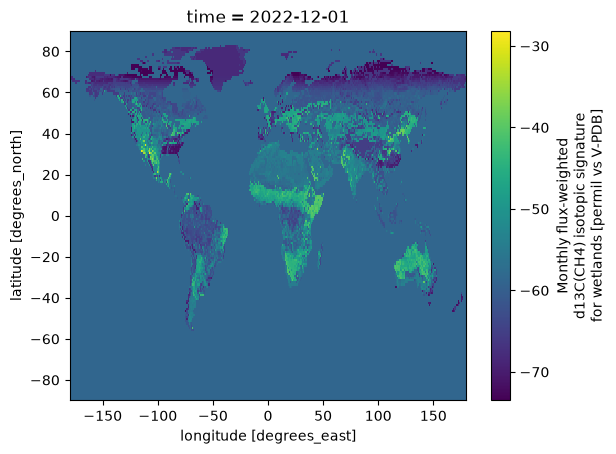

In [3]:
import cartopy.crs as ccrs
ds['sign_d13c_wet'].isel(time=-1).plot()
